<a href="https://colab.research.google.com/github/bayuaripermana/bayuaripermana/blob/main/ANALISIS_PENJUALAN_PRODUK_TOYOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/google colab/penjualan_mobil_toyota.csv')



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style="whitegrid")

print("Environment berhasil disiapkan!")

Environment berhasil disiapkan!


In [ ]:
df.head()

,Bulan,Penjualan
0,2011-01,27619
1,2011-02,25532
2,2011-03,32275
3,2011-04,21128
4,2011-05,19554


In [ ]:
# Informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Bulan      149 non-null    object
 1   Penjualan  149 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.5+ KB


In [ ]:
df.describe()

,Penjualan
count,149.00
mean,"28,402.85"
std,"7,579.40"
min,695.00
25%,"25,081.00"
50%,"29,362.00"
75%,"33,344.00"
max,"40,781.00"


In [ ]:
df.isnull().sum()

,0
Bulan,0
Penjualan,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
print("Total data:", len(df))
print("Periode awal:", df['Bulan'].min())
print("Periode akhir:", df['Bulan'].max())
print("Jumlah nilai unik:", df['Bulan'].nunique())

Total data: 149
Periode awal: 2011-01
Periode akhir: 2023-05
Jumlah nilai unik: 149


In [ ]:
df['Bulan'] = pd.to_datetime(
    df['Bulan'],
    format='%Y-%m'
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Bulan      149 non-null    datetime64[ns]
 1   Penjualan  149 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.5 KB


In [ ]:
df = df.sort_values('Bulan')

df = df.reset_index(drop=True)

In [ ]:
all_months = pd.date_range(
    start=df['Bulan'].min(),
    end=df['Bulan'].max(),
    freq='MS'
)

missing_months = all_months.difference(df['Bulan'])

print("Bulan yang hilang:", missing_months)

Bulan yang hilang: DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


In [ ]:
df['Tahun'] = df['Bulan'].dt.year

df['Nama_Bulan'] = df['Bulan'].dt.month_name()

df['Nomor_Bulan'] = df['Bulan'].dt.month

df.head()

,Bulan,Penjualan,Tahun,Nama_Bulan,Nomor_Bulan
0,2011-01-01,27619,2011,January,1
1,2011-02-01,25532,2011,February,2
2,2011-03-01,32275,2011,March,3
3,2011-04-01,21128,2011,April,4
4,2011-05-01,19554,2011,May,5


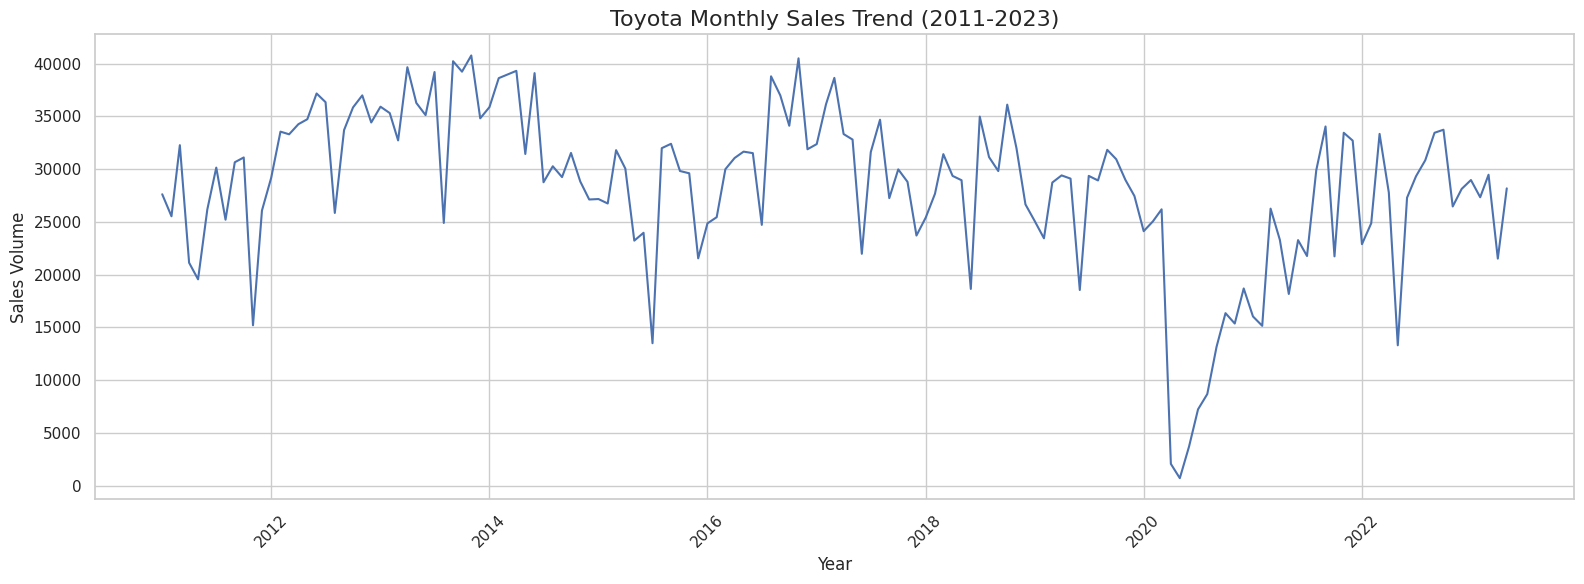

In [ ]:
plt.figure(figsize=(16,6))

plt.plot(
    df['Bulan'],
    df['Penjualan'],
    linewidth=1.5
)

plt.title(
    'Toyota Monthly Sales Trend (2011-2023)',
    fontsize=16
)

plt.xlabel('Year')
plt.ylabel('Sales Volume')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
yearly_sales = df.groupby('Tahun')['Penjualan'].agg(
    Total_Sales='sum',
    Average_Sales='mean',
    Maximum_Sales='max',
    Minimum_Sales='min'
)

yearly_sales

,Total_Sales,Average_Sales,Maximum_Sales,Minimum_Sales
Tahun,,,,
2011,310674,"25,889.50",32275,15195
2012,405414,"33,784.50",37176,25848
2013,434232,"36,186.00",40781,24899
2014,399119,"33,259.92",39323,27123
2015,321818,"26,818.17",32405,13495
2016,381570,"31,797.50",40510,24718
2017,371332,"30,944.33",38656,21974
2018,352161,"29,346.75",36119,18642
2019,331797,"27,649.75",31831,18541


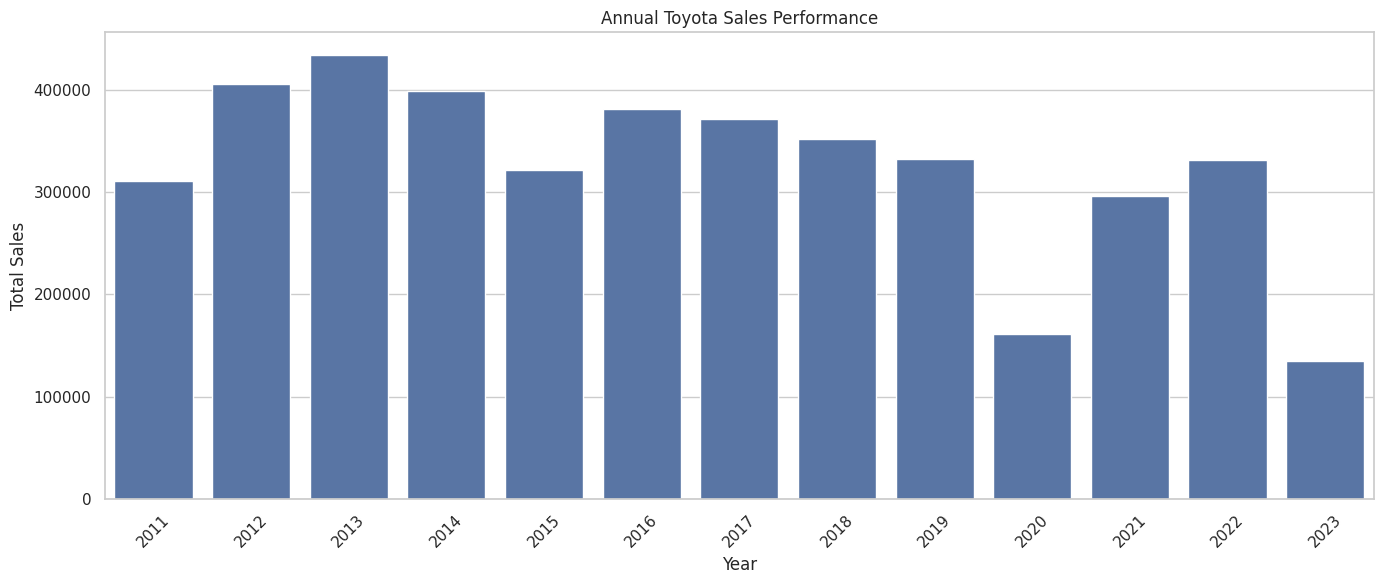

In [ ]:
plt.figure(figsize=(14,6))

sns.barplot(
    data=yearly_sales.reset_index(),
    x='Tahun',
    y='Total_Sales'
)

plt.title('Annual Toyota Sales Performance')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
yearly_sales['YoY_Growth'] = (
    yearly_sales['Total_Sales'].pct_change() * 100
)

yearly_sales

,Total_Sales,Average_Sales,Maximum_Sales,Minimum_Sales,YoY_Growth
Tahun,,,,,
2011,310674,"25,889.50",32275,15195,NaN
2012,405414,"33,784.50",37176,25848,30.49
2013,434232,"36,186.00",40781,24899,7.11
2014,399119,"33,259.92",39323,27123,-8.09
2015,321818,"26,818.17",32405,13495,-19.37
2016,381570,"31,797.50",40510,24718,18.57
2017,371332,"30,944.33",38656,21974,-2.68
2018,352161,"29,346.75",36119,18642,-5.16
2019,331797,"27,649.75",31831,18541,-5.78


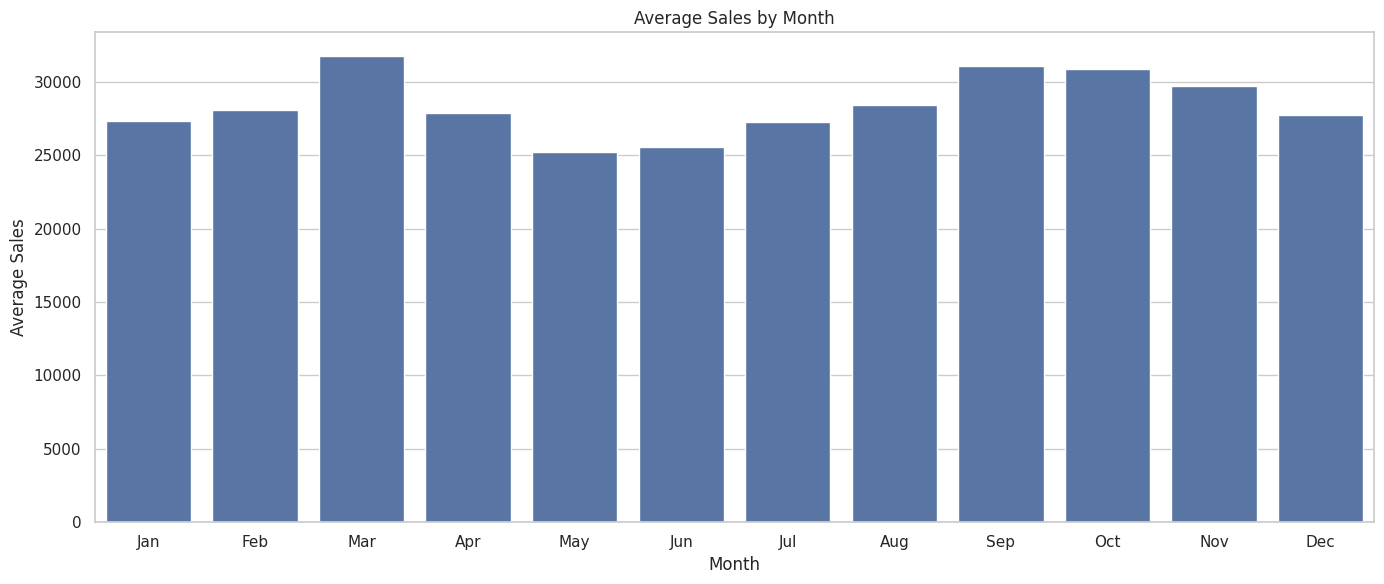

In [ ]:
monthly_sales = df.groupby('Nomor_Bulan')['Penjualan'].mean()

plt.figure(figsize=(14,6))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title('Average Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Sales')

plt.xticks(
    ticks=range(12),
    labels=[
        'Jan', 'Feb', 'Mar', 'Apr',
        'May', 'Jun', 'Jul', 'Aug',
        'Sep', 'Oct', 'Nov', 'Dec'
    ]
)

plt.tight_layout()
plt.show()

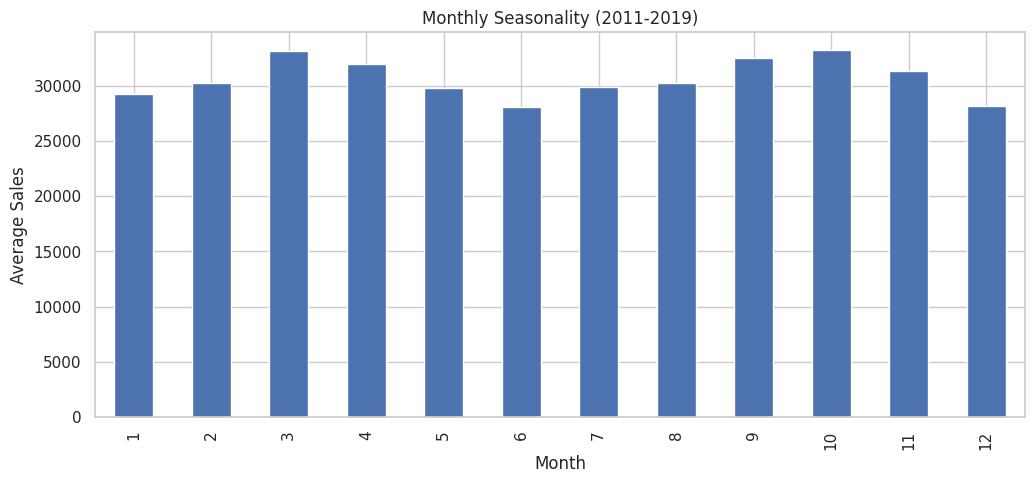

In [ ]:
pre_pandemic = df[df['Tahun'] <= 2019]

seasonality = pre_pandemic.groupby(
    'Nomor_Bulan'
)['Penjualan'].mean()

seasonality.plot(
    kind='bar',
    figsize=(12,5),
    title='Monthly Seasonality (2011-2019)'
)

plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.show()

In [56]:
df['YoY_Growth'] = (
    df['Penjualan'].pct_change(periods=12) * 100
)

df[['Bulan', 'Penjualan', 'YoY_Growth']].tail(20)

,Bulan,Penjualan,YoY_Growth
129,2021-10-01,21730,32.95
130,2021-11-01,33450,117.76
131,2021-12-01,32707,75.03
132,2022-01-01,22886,42.74
133,2022-02-01,24865,64.19
134,2022-03-01,33344,26.99
135,2022-04-01,27779,19.22
136,2022-05-01,13297,-26.81
137,2022-06-01,27290,17.27
138,2022-07-01,29326,34.75


In [57]:
df['YoY_Growth'] = (
    df['Penjualan'].pct_change(periods=12) * 100
)

df[['Bulan', 'Penjualan', 'YoY_Growth']].tail(20)

,Bulan,Penjualan,YoY_Growth
129,2021-10-01,21730,32.95
130,2021-11-01,33450,117.76
131,2021-12-01,32707,75.03
132,2022-01-01,22886,42.74
133,2022-02-01,24865,64.19
134,2022-03-01,33344,26.99
135,2022-04-01,27779,19.22
136,2022-05-01,13297,-26.81
137,2022-06-01,27290,17.27
138,2022-07-01,29326,34.75


In [58]:
df['MA_3'] = df['Penjualan'].rolling(
    window=3
).mean()

df['MA_12'] = df['Penjualan'].rolling(
    window=12
).mean()

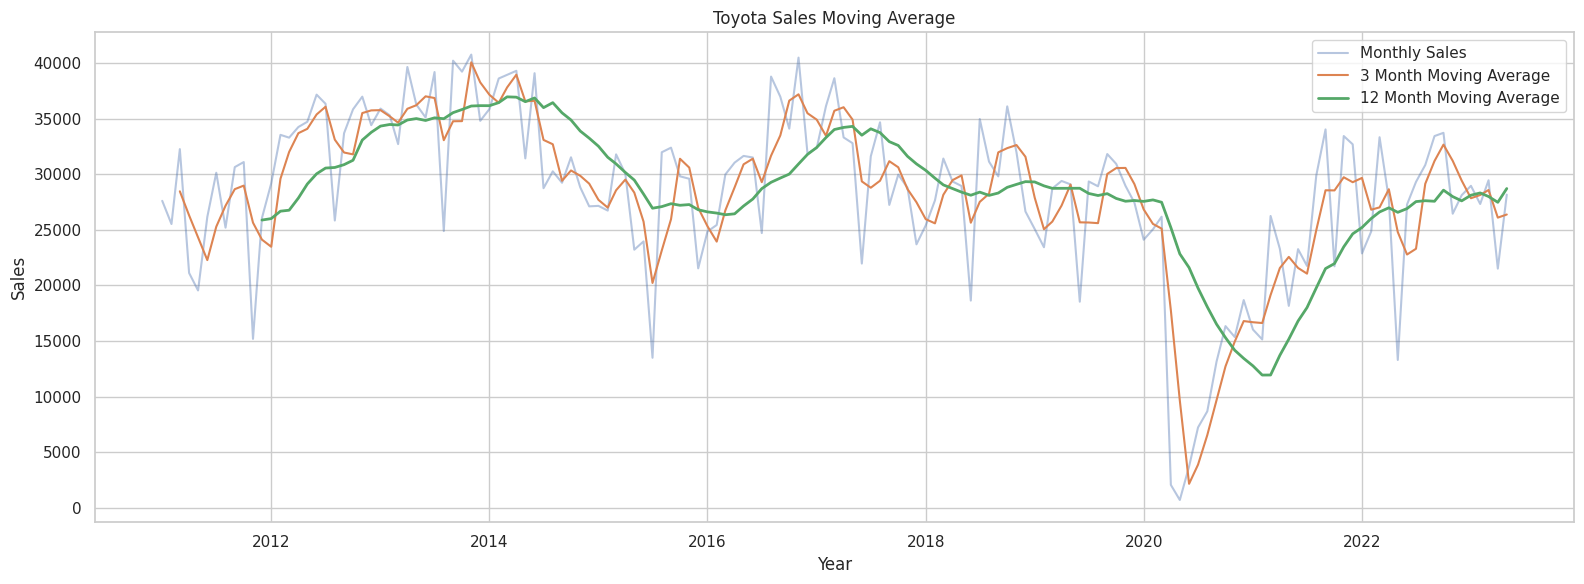

In [59]:
plt.figure(figsize=(16,6))

plt.plot(
    df['Bulan'],
    df['Penjualan'],
    alpha=0.4,
    label='Monthly Sales'
)

plt.plot(
    df['Bulan'],
    df['MA_3'],
    label='3 Month Moving Average'
)

plt.plot(
    df['Bulan'],
    df['MA_12'],
    linewidth=2,
    label='12 Month Moving Average'
)

plt.title('Toyota Sales Moving Average')

plt.xlabel('Year')
plt.ylabel('Sales')

plt.legend()
plt.tight_layout()
plt.show()

In [60]:
recovery = df[
    (df['Tahun'].between(2019, 2023)) &
    (df['Nomor_Bulan'] <= 5)
]

recovery_summary = recovery.groupby(
    'Tahun'
)['Penjualan'].sum().reset_index()

recovery_summary

,Tahun,Penjualan
0,2019,135767
1,2020,78111
2,2021,98903
3,2022,122171
4,2023,135473


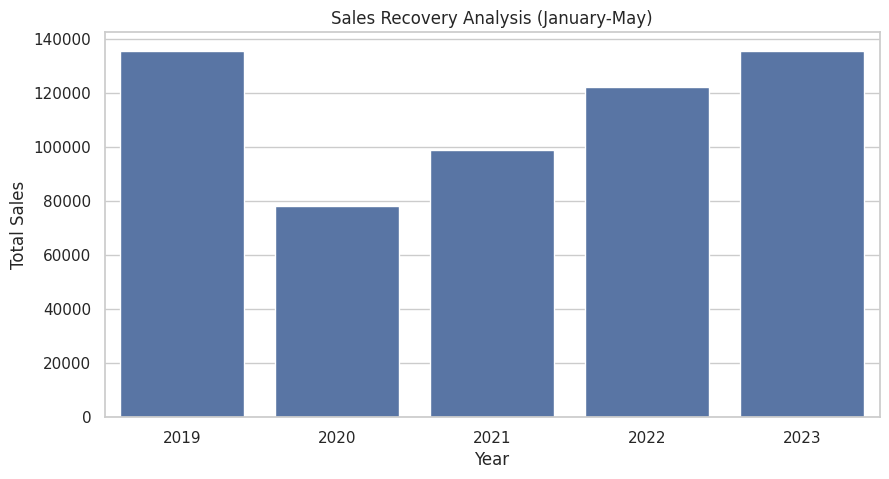

In [61]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=recovery_summary,
    x='Tahun',
    y='Penjualan'
)

plt.title('Sales Recovery Analysis (January-May)')
plt.xlabel('Year')
plt.ylabel('Total Sales')

plt.show()

In [62]:
Q1 = df['Penjualan'].quantile(0.25)
Q3 = df['Penjualan'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[
    (df['Penjualan'] < lower_bound) |
    (df['Penjualan'] > upper_bound)
]

outliers[['Bulan', 'Penjualan']]

,Bulan,Penjualan
111,2020-04-01,2053
112,2020-05-01,695
113,2020-06-01,3705
114,2020-07-01,7224
115,2020-08-01,8673


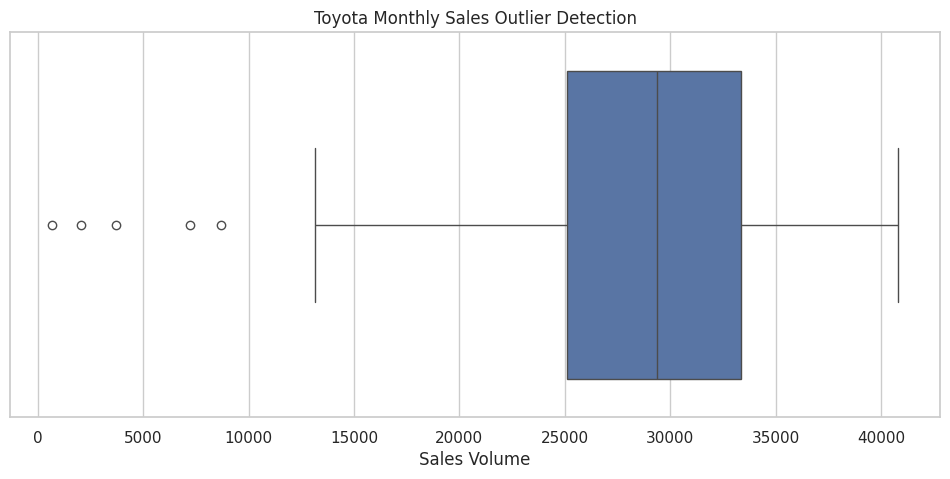

In [63]:
plt.figure(figsize=(12,5))

sns.boxplot(x=df['Penjualan'])

plt.title('Toyota Monthly Sales Outlier Detection')
plt.xlabel('Sales Volume')

plt.show()

In [64]:
# Membuat ringkasan penjualan tahunan
annual_report = df.groupby('Tahun').agg(
    Total_Sales=('Penjualan', 'sum'),
    Average_Sales=('Penjualan', 'mean'),
    Highest_Sales=('Penjualan', 'max'),
    Lowest_Sales=('Penjualan', 'min')
).reset_index()

# Menambahkan pertumbuhan tahunan
annual_report['YoY_Growth'] = (
    annual_report['Total_Sales'].pct_change() * 100
)

# Membuat Excel report
with pd.ExcelWriter(
    'Toyota_Sales_Analysis.xlsx',
    engine='openpyxl'
) as writer:

    df.to_excel(
        writer,
        sheet_name='Cleaned Data',
        index=False
    )

    annual_report.to_excel(
        writer,
        sheet_name='Annual Analysis',
        index=False
    )

    monthly_sales.reset_index().to_excel(
        writer,
        sheet_name='Monthly Seasonality',
        index=False
    )

    outliers.to_excel(
        writer,
        sheet_name='Outlier Analysis',
        index=False
    )

print("Report berhasil dibuat!")

Report berhasil dibuat!


In [65]:
from google.colab import files

files.download('Toyota_Sales_Analysis.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

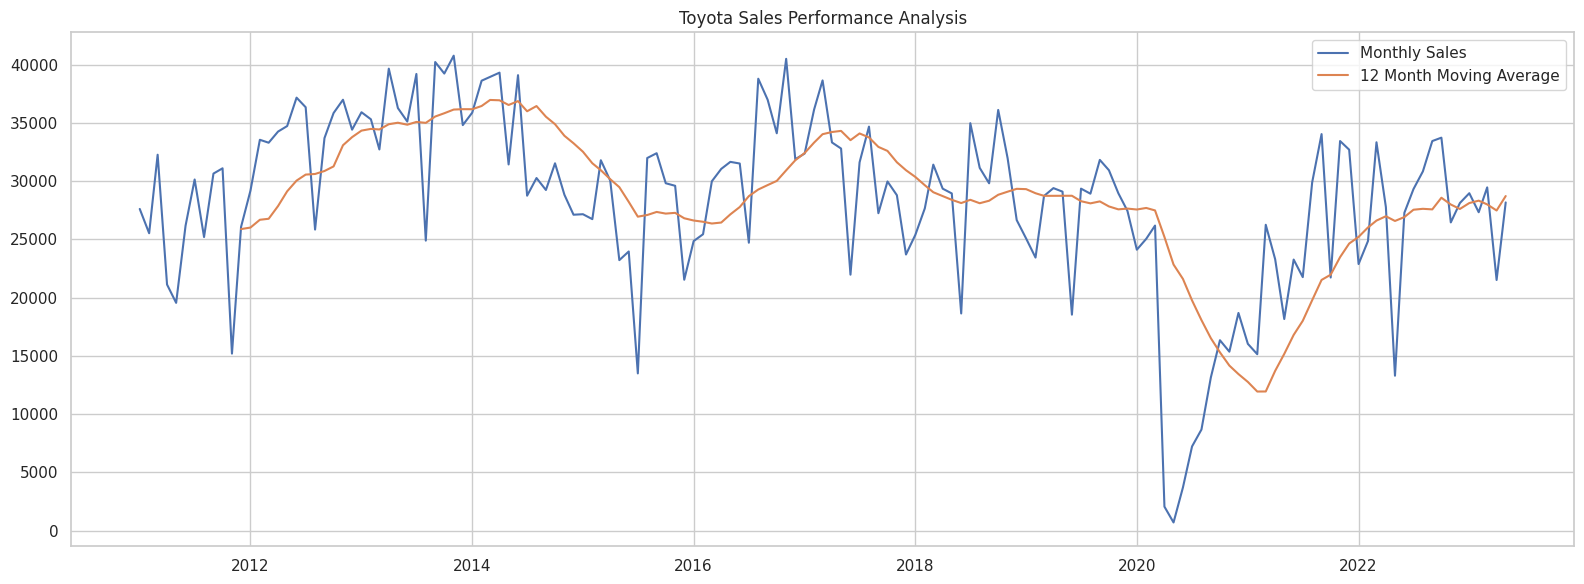

In [66]:
plt.figure(figsize=(16,6))

plt.plot(
    df['Bulan'],
    df['Penjualan'],
    label='Monthly Sales'
)

plt.plot(
    df['Bulan'],
    df['MA_12'],
    label='12 Month Moving Average'
)

plt.title('Toyota Sales Performance Analysis')

plt.legend()
plt.tight_layout()

plt.savefig(
    'Toyota_Sales_Trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()